# Exploratory Data Analysis

In this notebook, we will take a look at our data, preprocess it, and apply review selection.

In [63]:
# Install necessary libraries

!pip install rouge_score

In [64]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import random
from pprint import pprint
import textwrap

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.cluster import KMeans

from rouge_score import rouge_scorer

import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [65]:
train_df = pd.read_json('/content/drive/My Drive/WORK/AIML.com/112 - Review Summarization/data/amasum_train.json', orient='records', lines=True)
test_df = pd.read_json('/content/drive/My Drive/WORK/AIML.com/112 - Review Summarization/data/amasum_test.json', orient='records', lines=True)

In [66]:
train_df.head()

,website_summaries,customer_reviews,product_meta
0,[{'verdict': 'With its fun design and cheap pr...,[{'title': 'this is the absolute best phone fo...,{'title': 'Nokia Lumia 635 AT&T (Black) - Carr...
1,[{'verdict': 'This 7-piece countersink drill b...,"[{'title': 'Hot Scammy Garbage', 'text': 'Utte...",{'title': 'Werkzeug Countersink Drill Bits Set...
2,"[{'verdict': 'An affordable, waterproof hiking...",[{'title': 'I was very pleased with the first ...,{'title': 'KEEN Men's Targhee II Mid Waterproo...
3,[{'verdict': 'An elegantly designed armoire th...,[{'title': 'Looks okay But not the greatest qu...,"{'title': 'Sauder Harbor View Armoire, For TV'..."
4,[{'verdict': 'This is a reliable lint roller t...,[{'title': 'Buyers beware picture does NOT ref...,"{'title': 'Evercare Giant Lint Roller, 60 Shee..."


## Review Analysis

First, we will inspect the customer reviews:

In [ ]:
sample_product = train_df.iloc[0]
sample_reviews = sample_product['customer_reviews']

for i, review in enumerate(sample_reviews[:3]):
    print(f"Review {i}:")
    print(f"Title: {review['title']}")
    print("Text:")
    print(textwrap.fill(review['text'], width=100))

    print("\n" + "-" * 100 + "\n")

Review 0:
Title: this is the absolute best phone for the money in my opinion
Text:
As long as this is still available, this is the absolute best phone for the money in my opinion. I
researched seemingly forever for a low priced full-featured phone, and this fits the bill. The
Windows O.S. is seamless and easy to customize and navigate. I just bought two more for my wife and
daughter, who were always "borrowing" mine. I just have to chuckle when I see everyone swooning over
the latest exhorbitantly priced Apple phones, and paying the equvalent of a car payment to do the
same things this phone does. And my $30/ month plan is adequate for my business calling, email
checking and file sending needs, which is all I need it for.

----------------------------------------------------------------------------------------------------

Review 1:
Title: No Microsoft Support Buyer Beware
Text:
Effective July 31 2017 Microsoft no longer supports software on this phone. It took two hours at
At&t to get

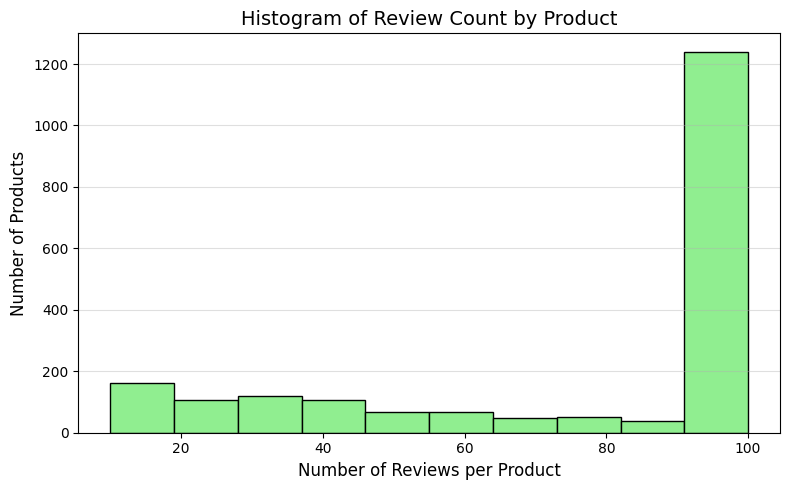

In [ ]:
# Create histogram of review counts per product

review_list = train_df['customer_reviews'].apply(lambda x: [review['text'] for review in x])
num_reviews = [len(review) for review in review_list]

plt.figure(figsize=(8, 5))

plt.hist(num_reviews, bins=10, color='lightgreen', edgecolor='black')

plt.title('Histogram of Review Count by Product', fontsize=14)
plt.xlabel('Number of Reviews per Product', fontsize=12)
plt.ylabel('Number of Products', fontsize=12)

plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()


The vast majority of products have the maximum 100 reviews. We will include only these products in our final dataset as we will be able to select the most informative reviews from them.

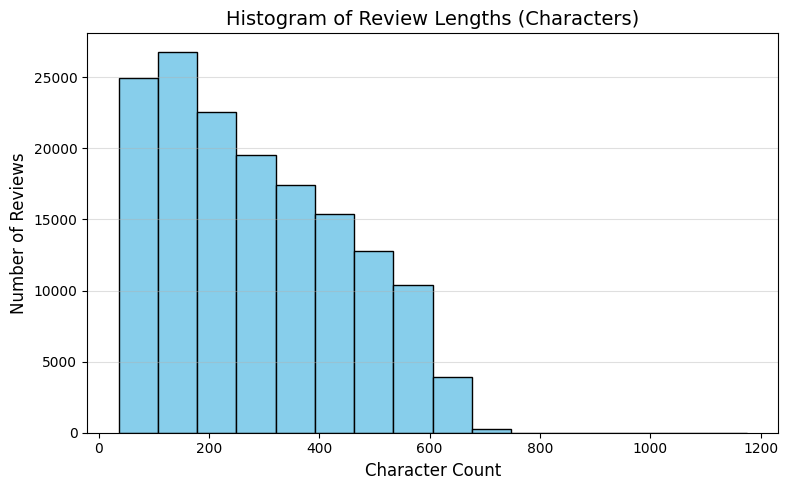

In [ ]:
# Create histogram of review lengths

all_reviews = [review for reviews in review_list for review in reviews]
review_lengths = [len(review) for review in all_reviews]

plt.figure(figsize=(8, 5))

plt.hist(review_lengths, bins=16, color='skyblue', edgecolor='black')

plt.title('Histogram of Review Lengths (Characters)', fontsize=14)
plt.xlabel('Character Count', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

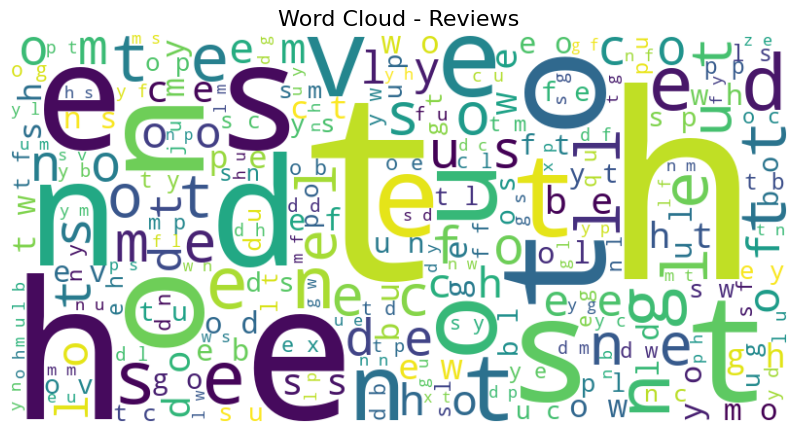

In [70]:
# Create review word cloud

all_review_text = " ".join(all_reviews)
review_wc = WordCloud(width=800, height=400, background_color='white').generate(" ".join(all_review_text))

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(review_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud - Reviews", fontsize=16)

plt.tight_layout()
plt.show()

## Summary Analysis

In [71]:
sample_products = train_df.iloc[:3]
sample_summaries = sample_products['website_summaries']

for i, summary in enumerate(sample_summaries):
    print(f"Summary {i}:")
    print(f"\nVerdict: {summary[0]['verdict']}")
    print("\nPros:")
    for pro in summary[0]['pros']:
      print(f"- {pro}")
    print("\nCons:")
    for con in summary[0]['cons']:
      print(f"- {con}")
    print("\n" + "-" * 100 + "\n")

Summary 0:

Verdict: With its fun design and cheap price, the Lumia 635 is a decent option to consider if you're after 4G LTE on a budget. It's only marginally more expensive than its near-identical 3G-only Lumia 630 sibling, so you should certainly opt for the 635. If you want a better selection of apps however, the Motorola Moto G is still the 4G phone to go for.

Pros:
- The Nokia Lumia 635 has an affordable price, its interchangeable cases are colourful and attractive and it has 4G LTE

Cons:
- Adding 4G LTE has meant the battery life has taken a hit, its screen resolution is unimpressive and its camera isn't really up to anything more than the odd Instagram snap

----------------------------------------------------------------------------------------------------

Summary 1:

Verdict: This 7-piece countersink drill bit set offers amazing versatility and won't break your budget.

Pros:
- Carbon steel construction delivers long-lasting strength and durability
- 3-point design ensures

While all summaries include the a verdict, pros, and cons, these items vary in length and format. Our first verdict consists of three relatively long sentences, while the other two are very succint. The pros and cons of the first summary are also not separated into list items. We can address this second point by concatenating pros and cons into a single string that will all read similarly.

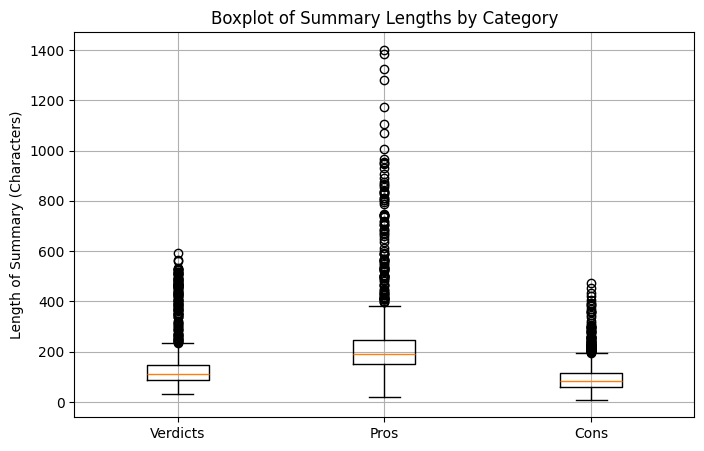

In [72]:
# Box plot of lengths of verdicts, pros, and cons

verdict_list = train_df['website_summaries'].apply(lambda x: x[0]['verdict']).tolist()
verdict_lengths = [len(verdict) for verdict in verdict_list]

pros_list = train_df['website_summaries'].apply(lambda x: x[0]['pros']).tolist()
pros_lengths = [len(" ".join(pro_summary)) for pro_summary in pros_list]

cons_list = train_df['website_summaries'].apply(lambda x: x[0]['cons']).tolist()
cons_lengths = [len(" ".join(con_summary)) for con_summary in cons_list]

data = [verdict_lengths, pros_lengths, cons_lengths]
labels = ['Verdicts', 'Pros', 'Cons']

plt.figure(figsize=(8, 5))
plt.boxplot(data, tick_labels=labels)
plt.ylabel('Length of Summary (Characters)')
plt.title('Boxplot of Summary Lengths by Category')
plt.grid(True)
plt.show()

There are several very long "pros" summaries. These can distort evaluation with ROUGE, so we will truncate longer summaries so length variance is lower.

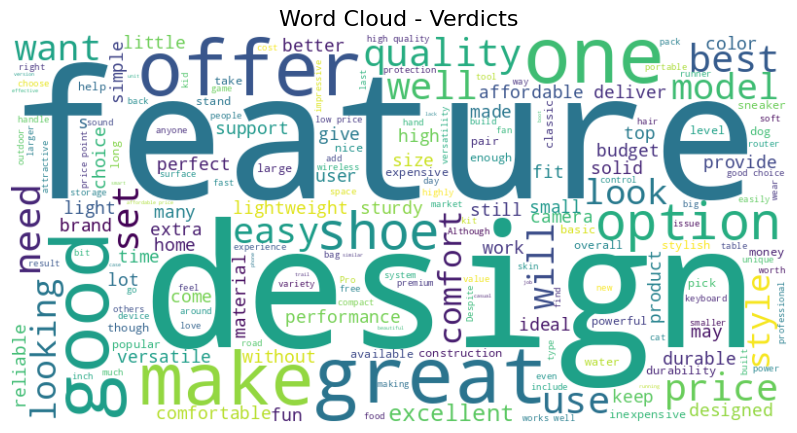

In [73]:
# Create summary word cloud
all_verdicts_text = " ".join(verdict_list)
verdict_wc = WordCloud(width=800, height=400, background_color='white').generate(all_verdicts_text)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 2)
plt.imshow(verdict_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud - Verdicts", fontsize=16)

plt.tight_layout()
plt.show()

## Preprocessing

We only care about the reviews and the summaries (verdicts, pros, cons). We will create columns for verdicts, pros, cons, and for the review texts. All other columns can be removed. We will also set minimum and maximum review lengths - this helps ensure our model inputs are similarly sized.

In [74]:
def clean_df(df):
    df['verdict'] = df['website_summaries'].apply(lambda x: x[0]['verdict'])
    df['pros'] = df['website_summaries'].apply(lambda x: x[0]['pros'])
    df['cons'] = df['website_summaries'].apply(lambda x: x[0]['cons'])

    df['review_text'] = df['customer_reviews'].apply(lambda x: [review['text'] for review in x])

    df['num_reviews'] = [len(review) for review in df['review_text']]

    df = df.drop(['product_meta', 'customer_reviews', 'website_summaries'], axis=1)

    df = df.reset_index(drop=True)

    return df

In [75]:
train_df_clean = clean_df(train_df)
test_df_clean = clean_df(test_df)

In [76]:
def create_subset(df, min_reviews, min_review_len, max_review_len):
    df = df.loc[df['num_reviews'] >= min_reviews]
    df['review_text'] = df['review_text'].apply(lambda reviews: [r for r in reviews if min_review_len <= len(r) <= max_review_len])

    return df

In [77]:
train_df_subset = create_subset(train_df_clean, min_reviews=90, min_review_len=100, max_review_len=600)
test_df_subset = create_subset(test_df_clean, min_reviews=90, min_review_len=100, max_review_len=600)

## Review Selection

### Random

Finally, we will apply our review selection methods. The simplest method is to randomly select a subset of reviews:

In [78]:
# Method 1: Random

def random_select(df, k=15):
    df['random_reviews'] = df['review_text'].apply(lambda x: random.sample(x, k))

    return df

### Clustering

A more effective way to sample is to create clusters of reviews and sample from those clusters. We will use [K-Means](https://www.geeksforgeeks.org/machine-learning/k-means-clustering-introduction/) as our clustering algorithm, which partitions the data into a predefined number of clusters by minimizing the variance within each cluster. It iteratively assigns each data point to the nearest cluster centroid and updates the centroids until convergence. Once these clusters are defined, we select the review that is closest to the center of each cluster. This effectively maximizes the diversity between selected reviews by ensuring that they all come from different clusters.

Due to its prioritization of diversity, we will use this selection method for our deep learning models, which benefit from a wide variety of reviews.

(possibly add visual/YT video here)

In [79]:
# Method 2: Clustering

def cluster_row(reviews, k=15):
    # Cluster reviews to find diverse groups
    vectorizer = TfidfVectorizer(stop_words='english', max_features=1000)
    tfidf_matrix = vectorizer.fit_transform(reviews)

    # Cluster into groups
    kmeans = KMeans(n_clusters=min(k, len(reviews)//2))
    clusters = kmeans.fit_predict(tfidf_matrix)

    # Select closest review to each cluster center
    selected_reviews = []
    for i in range(kmeans.n_clusters):
        cluster_indices = np.where(clusters == i)[0]
        if len(cluster_indices) > 0:
            # Find review closest to cluster center
            cluster_center = kmeans.cluster_centers_[i]
            distances = [np.linalg.norm(tfidf_matrix[idx].toarray() - cluster_center)
                        for idx in cluster_indices]
            best_idx = cluster_indices[np.argmin(distances)]
            selected_reviews.append(reviews[best_idx])

    return selected_reviews[:k]

def cluster_select(df, limit=15):
    df['cluster_reviews'] = df['review_text'].apply(cluster_row)

    return df

## Similarity Regression

Another way to select reviews is to rank them by how similar they are to our gold summaries. Since the human written summaries are intentionally clear and informative, ideal reviews should mirror the summaries. However, this cannot be done directly as the gold summaries cannot be utilized by our summarization models. We can approximate similarity by training a regression model on our train set and use it to predict similarity rankings for our test set.

We will use ROUGE-L as our similarity metric, which measures the longest common subsequence (LCS) between the predicted and reference texts. This captures sentence-level structure similarity and rewards fluency and recall of in-order matching words. We will use a basic linear regression model, trained on the [TFIDF](https://www.geeksforgeeks.org/machine-learning/understanding-tf-idf-term-frequency-inverse-document-frequency/) features of reviews and summaries.

Due to its prioritization of similarity to gold summaries, we will use this selection method for our traditional extractive models since they are more prone to selecting uninformative sentences. Since our these models are unsupervised, we can train the similarity regression model on the entire train set as the model will only see the test data.

In [80]:
# Method 5: Similarity Regression

def compute_similarity(df):
    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

    similarities = []
    for _, row in df.iterrows():
        reviews = row['review_text']
        summary = " ".join(str(row[col]) for col in ['verdict', 'pros', 'cons'])

        # Compute ROUGE-L score between each review and the summary
        row_scores = []
        for review in reviews:
            if isinstance(review, str) and isinstance(summary, str):
                score = scorer.score(summary, review)['rougeL'].fmeasure
                row_scores.append(score)
            else:
                row_scores.append(0.0)  # Handle NaNs or bad data

        similarities.append(row_scores)

    df['similarity'] = similarities
    return df


def train_selector(df, vectorizer):
    df = compute_similarity(df)
    all_reviews = [review for reviews in df['review_text'] for review in reviews]
    X = vectorizer.fit_transform(all_reviews)
    y = [sim for row_sims in df['similarity'] for sim in row_sims]

    model = LinearRegression()
    model.fit(X, y)

    return model, vectorizer


def regression_select(train_df, test_df, k=15):

    vectorizer = TfidfVectorizer(max_features=300)
    model, vectorizer = train_selector(train_df, vectorizer)

    selected_reviews = []

    for reviews in test_df['review_text']:
        tfidf_reviews = vectorizer.transform(reviews)
        rankings = model.predict(tfidf_reviews)
        top_reviews = [review for rank, review in sorted(zip(rankings, reviews), reverse=True)[:k]]
        selected_reviews.append(top_reviews)

    test_df['similarity_reviews'] = selected_reviews

    return test_df

In [81]:
train_df_final = random_select(train_df_subset)
test_df_final = random_select(test_df_subset)

train_df_final = cluster_select(train_df_final)
test_df_final = cluster_select(test_df_final)

test_df_final = regression_select(train_df_final, test_df_final)

In [85]:
train_df_final.to_json('/content/drive/My Drive/WORK/AIML.com/112 - Review Summarization/data/amasum_train_processed.json', orient="records", lines=True)
test_df_final.to_json('/content/drive/My Drive/WORK/AIML.com/112 - Review Summarization/data/amasum_test_processed.json', orient="records", lines=True)